## 1. Load the data

A first look at PORTIA: how much data we have, what the labels look like, and a few recordings.

Run `uv run python data-prep/prepare.py` from the repo root first, then run this notebook top to bottom. The approved representative_v2 preparation supplies development views, audio diagnostics, exclusions, and coverage goals. All target and coverage summaries below use training and validation only.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
from IPython.display import Audio, display
from scipy import signal

root = Path.cwd()
if root.name == 'eda':
    root = root.parent
data = root / 'data'
processed = data / 'processed'
audio_dir = data / 'PORTIA_Clean_Release' / 'audio'
classes = ['tug', 'pilot', 'cargo', 'passenger', 'support', 'tanker', 'other']
splits = ['train', 'val', 'test']
development_splits = ['train', 'val']
views = ['training', 'natural', 'coverage']
sns.set_theme(style='whitegrid')

# Keep vessel IDs as strings and recording times as datetimes.
id_columns = {'primary_mmsi': 'string', 'all_mmsis': 'string'}
manifest = pd.read_csv(processed / 'manifests.csv', dtype=id_columns)
pilot = pd.read_csv(processed / 'pilot.csv', dtype=id_columns)
audio_quality = pd.read_csv(processed / 'audio_quality.csv')
exclusions = pd.read_csv(processed / 'exclusions.csv')
metadata_review = pd.read_csv(processed / 'metadata_review.csv')
coverage_goals = pd.read_csv(processed / 'coverage_goals.csv')
sampling_summary = pd.read_csv(processed / 'sampling_summary.csv')
for table in [manifest, pilot]:
    table['window_start'] = pd.to_datetime(table['window_start'], utc=True)

# Test membership is used only for identity checks, never for target summaries.
development = manifest.loc[manifest['temporal_split'].isin(development_splits)].copy()
selected = pilot.loc[
    pilot['split'].isin(development_splits) & pilot['view'].isin(views)
].copy()
display(pd.DataFrame({
    'rows': [len(development), len(selected)],
    'unique_wavs': [development['audio_path'].nunique(), selected['audio_path'].nunique()],
}, index=['development metadata', 'selected development']))
display(development.head())
display(sampling_summary.loc[
    sampling_summary['split'].isin(development_splits) & sampling_summary['view'].isin(views),
    ['task', 'split', 'view', 'rows', 'days', 'time_bins', 'vessel_ids'],
])

,rows,unique_wavs
development metadata,101711,88615
selected development,1512,1506


,audio_path,source,is_background,n_vessels,primary_mmsi,primary_class,primary_dist,all_mmsis,timestamp,tug,...,other_dist,split,binary_label,task,official_split,window_start,recording_day,time_bin,temporal_split,conflicting_target
0,20250518_090234.599908368.wav,windowed,1,0,<NA>,NaN,NaN,225998087,2025-05-18 09:02:34+00:00,0,...,NaN,train,0.0,binary,train,2025-05-18 09:02:34.599908368+00:00,2025-05-18,2025-05-18 09:00:00+00:00,train,False
1,20250518_090237.644671816.wav,windowed,1,0,<NA>,NaN,NaN,225998087,2025-05-18 09:02:37+00:00,0,...,NaN,train,0.0,binary,train,2025-05-18 09:02:37.644671816+00:00,2025-05-18,2025-05-18 09:00:00+00:00,train,False
2,20250518_090243.736697350.wav,windowed,1,0,<NA>,NaN,NaN,225998087,2025-05-18 09:02:43+00:00,0,...,NaN,train,0.0,binary,train,2025-05-18 09:02:43.736697350+00:00,2025-05-18,2025-05-18 09:00:00+00:00,train,False
3,20250518_090246.781061066.wav,windowed,1,0,<NA>,NaN,NaN,225998087,2025-05-18 09:02:46+00:00,0,...,NaN,train,0.0,binary,train,2025-05-18 09:02:46.781061066+00:00,2025-05-18,2025-05-18 09:00:00+00:00,train,False
4,20250518_090249.827123897.wav,windowed,1,0,<NA>,NaN,NaN,225998087,2025-05-18 09:02:49+00:00,0,...,NaN,train,0.0,binary,train,2025-05-18 09:02:49.827123897+00:00,2025-05-18,2025-05-18 09:00:00+00:00,train,False


,task,split,view,rows,days,time_bins,vessel_ids
1,binary,train,training,300,9,300,88.0
2,binary,val,natural,200,5,143,56.0
4,multilabel,train,training,300,9,300,122.0
5,multilabel,val,coverage,2,2,2,2.0
6,multilabel,val,natural,200,4,165,69.0
8,single,train,training,300,9,300,73.0
9,single,val,coverage,10,2,3,1.0
10,single,val,natural,200,4,121,32.0


## 2. Labels and missing values

Labels come from AIS vessel reports, not verified audible sources. A primary vessel type does not mean there is only one vessel.

Missing distances are often expected when a class is absent. `binary_label` only applies to the binary task. Keep unknown targets missing rather than filling them with zero.

In [2]:
# Show missing values in development metadata, separately for each task.
missing = pd.DataFrame({
    task: group.isna().sum() for task, group in development.groupby('task')
})
display(missing.loc[missing.sum(axis=1).gt(0)])

binary = development.loc[development['task'].eq('binary')]
single = development.loc[development['task'].eq('single')]
multilabel = development.loc[development['task'].eq('multilabel')]
conflicts = development.loc[development['conflicting_target']]
print(f'Missing development binary targets: {binary["binary_label"].isna().sum():,}')
print(f'Conflicting development WAVs: {conflicts["audio_path"].nunique():,}')
multi_vessel_fraction = single['n_vessels'].gt(1).mean()
print(f'Single-target development rows with multiple vessels: {multi_vessel_fraction:.1%}')

# Match preparation: require complete, known targets and exclude conflicts.
valid_binary = development['task'].eq('binary') & development['binary_label'].isin([0, 1])
valid_single = development['task'].eq('single') & development['primary_class'].isin(classes)
valid_multilabel = (
    development['task'].eq('multilabel') & development[classes].isin([0, 1]).all(axis=1)
)
eligible = development.loc[
    (valid_binary | valid_single | valid_multilabel) & ~development['conflicting_target']
].drop_duplicates(['task', 'audio_path']).copy()
selected = selected.drop_duplicates(['task', 'audio_path', 'view']).copy()

# Match development identities so no reserved-test reasons are summarized.
development_keys = development[['task', 'audio_path']].drop_duplicates()
development_exclusions = exclusions.merge(
    development_keys, on=['task', 'audio_path'], how='inner',
)
print('Development exclusion reasons:')
reason_counts = development_exclusions.groupby(['task', 'reason']).size().rename('rows')
display(reason_counts.to_frame())
development_review = metadata_review.merge(
    development_keys, on=['task', 'audio_path'], how='inner',
)
print('Development metadata review reasons:')
review_counts = development_review.groupby(['task', 'reason']).size().rename('rows')
display(review_counts.to_frame())
development_goals = coverage_goals.loc[coverage_goals['split'].isin(development_splits)]
met = development_goals['met'].astype('string').str.lower().isin(['true', '1'])
unmet = development_goals.loc[~met]
print(
    'Unmet development coverage goals:' if len(unmet)
    else 'No unmet development coverage goals.'
)
if len(unmet):
    display(unmet[['task', 'split', 'goal', 'required', 'achieved', 'met']])

,binary,multilabel,single
primary_mmsi,17351,0,0
primary_class,17351,0,0
primary_dist,18930,3213,7821
all_mmsis,17225,0,0
tug_dist,22748,11448,25169
pilot_dist,25360,15977,23651
cargo_dist,27523,19090,30080
passenger_dist,29818,25515,32268
support_dist,30770,25029,29980
tanker_dist,31822,27569,32737


Missing development binary targets: 1,579
Conflicting development WAVs: 283
Single-target development rows with multiple vessels: 17.5%
Development exclusion reasons:


rows
task       reason                                                 
binary     conflicting_target                                  566
           invalid_target                                     1579
multilabel Expected three seconds, four channels, and 32 kHz     1

Development metadata review reasons:


,,rows
task,reason,


No unmet development coverage goals.


Development class support: multilabel positives can overlap.


view                        available  training  natural  coverage
task       split class                                            
binary     train 0            14411.0     150.0      NaN       NaN
                 1            11201.0     150.0      NaN       NaN
           val   0             2657.0       NaN     87.0       NaN
                 1             3399.0       NaN    113.0       NaN
multilabel train cargo         9465.0     107.0      NaN       NaN
                 other          907.0      22.0      NaN       NaN
                 passenger     4211.0      51.0      NaN       NaN
                 pilot        12072.0     144.0      NaN       NaN
                 support       4882.0      68.0      NaN       NaN
                 tanker        2717.0      30.0      NaN       NaN
                 tug          15782.0     192.0      NaN       NaN
           val   cargo         2763.0       NaN     77.0       0.0
                 other          360.0       NaN     13.0       0.0
                 passenger     1592.0       NaN     39.0       0.0
                 pilot         3269.0       NaN    104.0       0.0
                 support       1407.0       NaN     35.0       0.0
                 tanker        1032.0       NaN     35.0       0.0
                 tug           4088.0       NaN    125.0       2.0
single     train cargo         4527.0      40.0      NaN       NaN
                 other          314.0      20.0      NaN       NaN
                 passenger     2183.0      25.0      NaN       NaN
                 pilot         9317.0      91.0      NaN       NaN
                 support       4535.0      39.0      NaN       NaN
                 tanker        2943.0      26.0      NaN       NaN
                 tug           6127.0      59.0      NaN       NaN
           val   cargo         1129.0       NaN     33.0       0.0
                 other           27.0       NaN      0.0      10.0
                 passenger      899.0       NaN     35.0       0.0
                 pilot         1518.0       NaN     41.0       0.0
                 support       1482.0       NaN     30.0       0.0
                 tanker         584.0       NaN     26.0       0.0
                 tug            995.0       NaN     35.0       0.0

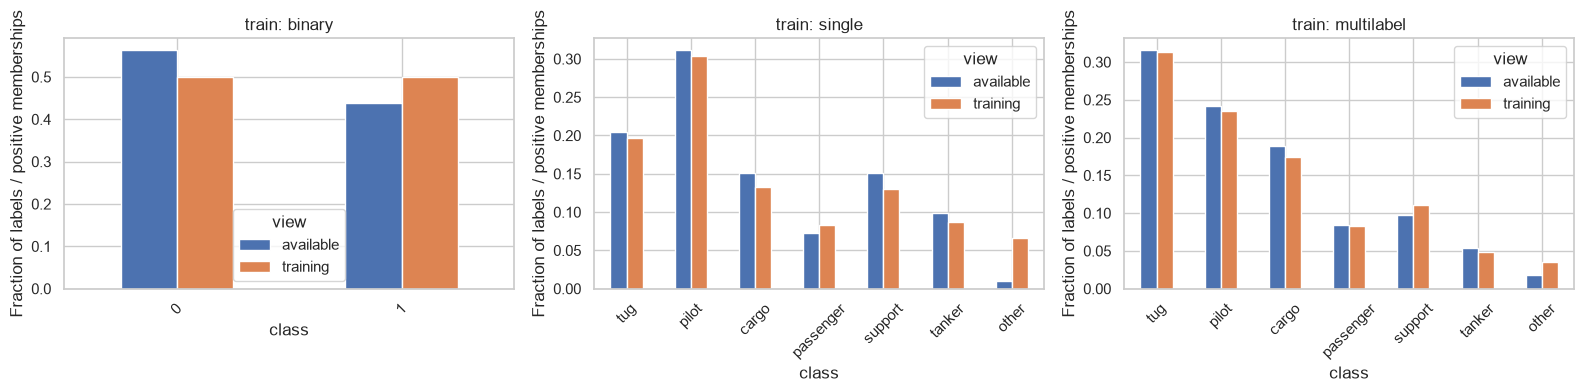

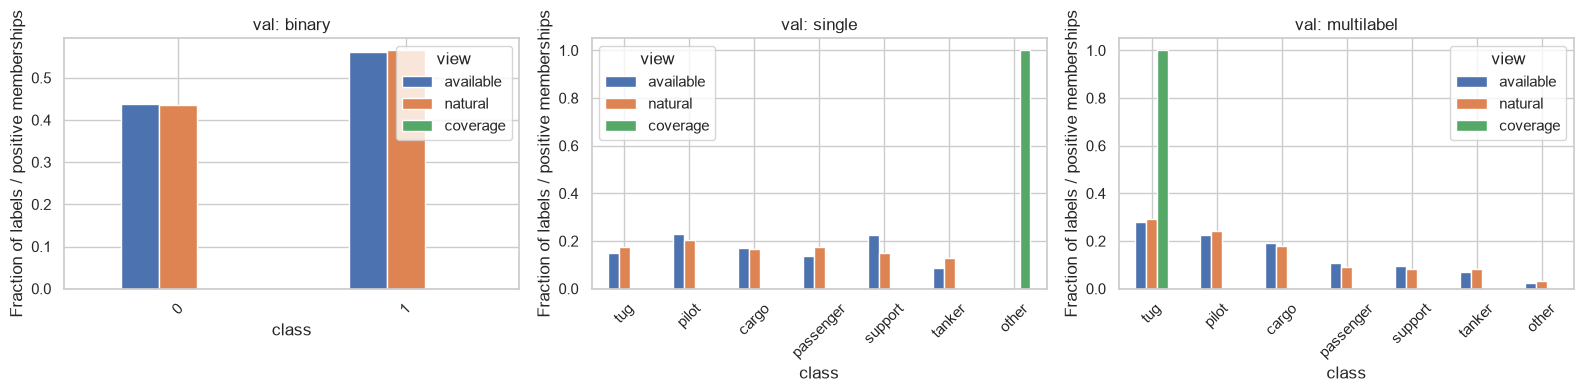

In [3]:
# Available pools and selected views stay separate, especially natural vs coverage.
available = eligible.assign(split=eligible['temporal_split'], view='available')
comparison = pd.concat([available, selected], ignore_index=True)
view_order = ['available', 'training', 'natural', 'coverage']
class_rows = []
for (task, split, view), group in comparison.groupby(['task', 'split', 'view']):
    if task == 'binary':
        counts = group['binary_label'].value_counts().reindex([0, 1], fill_value=0)
    elif task == 'single':
        counts = group['primary_class'].value_counts().reindex(classes, fill_value=0)
    else:
        counts = group[classes].eq(1).sum()
    for label, count in counts.items():
        class_rows.append({
            'task': task, 'split': split, 'view': view, 'class': str(label), 'rows': count,
        })
class_counts = pd.DataFrame(class_rows)
print('Development class support: multilabel positives can overlap.')
class_table = class_counts.pivot(
    index=['task', 'split', 'class'], columns='view', values='rows',
)
display(class_table.reindex(columns=view_order))

# Separate panels keep enriched and natural validation distributions distinct.
for split in development_splits:
    split_views = ['available', 'training']
    if split == 'val':
        split_views = ['available', 'natural', 'coverage']
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, task in zip(axes, ['binary', 'single', 'multilabel']):
        counts = class_counts.loc[
            class_counts['task'].eq(task) & class_counts['split'].eq(split)
        ]
        counts = counts.pivot(index='class', columns='view', values='rows')
        labels = ['0', '1'] if task == 'binary' else classes
        counts = counts.reindex(index=labels, columns=split_views)
        proportions = counts.div(counts.sum(axis=0).replace(0, np.nan), axis=1)
        proportions.plot.bar(ax=ax, rot=45, title=f'{split}: {task}')
        ax.set_ylabel('Fraction of labels / positive memberships')
    fig.tight_layout()
    plt.show()

## 3. Splits and shared recordings

The official splits can share recordings. Preparation instead splits whole recording days in chronological order, using the same frozen assignment for all three tasks: training May 16-27, validation May 28-June 2, and reserved test June 3, 9, 10, and 12, 2025.

Compare the eligible development pools with each selected view. Training is coverage-oriented; natural validation is the main prevalence sample; coverage validation is a separate supplement. Do not pool the two validation distributions. These samples cover the available recording period, not all ports, seasons, or audible vessels. Five-minute bins spread selections but do not prove independence.

Only split identities are checked for test recordings. Test labels and test audio remain uninspected.

official_split,train,val,test
task,,,
binary,25593,5506,5511
multilabel,19609,8141,7246
single,20740,11790,7466


WAVs shared across official splits: 147
manifest: WAVs crossing temporal splits = 0
manifest: recording days crossing temporal splits = 0
pilot: WAVs crossing temporal splits = 0
pilot: recording days crossing temporal splits = 0
Pilot split differs from temporal_split: 0
Natural/coverage shared task-WAVs: 0
Development rows, days, and time bins by view:


rows  days  time_bins
task       split view                             
binary     train available  25612     9       1754
                 training     300     9        300
           val   available   6056     6        519
                 natural      200     5        143
multilabel train available  24663     9       1685
                 training     300     9        300
           val   available   6655     6        510
                 coverage       2     2          2
                 natural      200     4        165
single     train available  29946     9       1059
                 training     300     9        300
           val   available   6634     6        265
                 coverage      10     2          3
                 natural      200     4        121

Development available versus selected: recording_day


view                            available  training  natural  coverage
task       split recording_day                                        
binary     train 2025-05-16           800        19        0         0
                 2025-05-17          4446        35        0         0
                 2025-05-18          4672        36        0         0
                 2025-05-19          3885        35        0         0
                 2025-05-20          2501        35        0         0
                 2025-05-21          2158        35        0         0
                 2025-05-22          2912        35        0         0
                 2025-05-23          2136        35        0         0
                 2025-05-27          2102        35        0         0
           val   2025-05-28          2882         0       96         0
                 2025-05-29          1779         0       57         0
                 2025-05-30          1333         0       43         0
                 2025-05-31            17         0        1         0
                 2025-06-01            44         0        3         0
                 2025-06-02             1         0        0         0
multilabel train 2025-05-16          2326        33        0         0
                 2025-05-17          4156        34        0         0
                 2025-05-18          3514        34        0         0
                 2025-05-19          3653        33        0         0
                 2025-05-20          2178        33        0         0
                 2025-05-21          1600        33        0         0
                 2025-05-22          2988        34        0         0
                 2025-05-23          1882        33        0         0
                 2025-05-27          2366        33        0         0
           val   2025-05-28          3544         0      109         0
                 2025-05-29          1141         0       37         1
                 2025-05-30          1932         0       53         1
                 2025-05-31            26         0        1         0
                 2025-06-01             5         0        0         0
                 2025-06-02             7         0        0         0
single     train 2025-05-16          2708        33        0         0
                 2025-05-17          7446        34        0         0
                 2025-05-18          4763        34        0         0
                 2025-05-19          3283        33        0         0
                 2025-05-20          1942        33        0         0
                 2025-05-21          2196        33        0         0
                 2025-05-22          3708        34        0         0
                 2025-05-23          1700        33        0         0
                 2025-05-27          2200        33        0         0
           val   2025-05-28          3410         0      114         0
                 2025-05-29          1659         0       46         4
                 2025-05-30          1444         0       38         6
                 2025-05-31            69         0        2         0
                 2025-06-01            21         0        0         0
                 2025-06-02            31         0        0         0

...

view                                    available  training  natural  coverage
task   split time_bin                                                         
binary train 2025-05-16 16:30:00+00:00          1         0        0         0
             2025-05-16 16:35:00+00:00         81         1        0         0
             2025-05-16 16:40:00+00:00         19         1        0         0
             2025-05-16 16:45:00+00:00          2         0        0         0
             2025-05-16 16:50:00+00:00         10         0        0         0
...                                           ...       ...      ...       ...
single val   2025-06-01 08:10:00+00:00          4         0        0         0
             2025-06-01 08:30:00+00:00          4         0        0         0
             2025-06-01 08:35:00+00:00         13         0        0         0
             2025-06-02 08:40:00+00:00          8         0        0         0
             2025-06-02 08:45:00+00:00         23         0        0         0

[5792 rows x 4 columns]

Development available versus selected: vessel_count_group


view                                 available  training  natural  coverage
task       split vessel_count_group                                        
binary     train 0                       14411       150        0         0
                 1                        2656        32        0         0
                 2                        2730        38        0         0
                 3+                       5815        80        0         0
           val   0                        2657         0       87         0
                 1                         781         0       23         0
                 2                         802         0       27         0
                 3+                       1816         0       63         0
multilabel train 1                        6935        88        0         0
                 2                        5758        66        0         0
                 3+                      11970       146        0         0
           val   1                        1576         0       48         2
                 2                        1544         0       46         0
                 3+                       3535         0      106         0
single     train 1                       23975       252        0         0
                 2                        2281        13        0         0
                 3+                       3690        35        0         0
           val   1                        6205         0      189        10
                 2                         125         0        4         0
                 3+                        304         0        7         0

Unique AIS identifiers, not unique audible vessels:


,task,split,view,unique_ids,source
0,binary,train,available,162,all_mmsis
1,binary,train,training,88,all_mmsis
2,binary,val,available,76,all_mmsis
3,binary,val,natural,56,all_mmsis
4,multilabel,train,available,164,all_mmsis
5,multilabel,train,training,122,all_mmsis
6,multilabel,val,available,78,all_mmsis
7,multilabel,val,coverage,2,all_mmsis
8,multilabel,val,natural,69,all_mmsis
9,single,train,available,125,all_mmsis


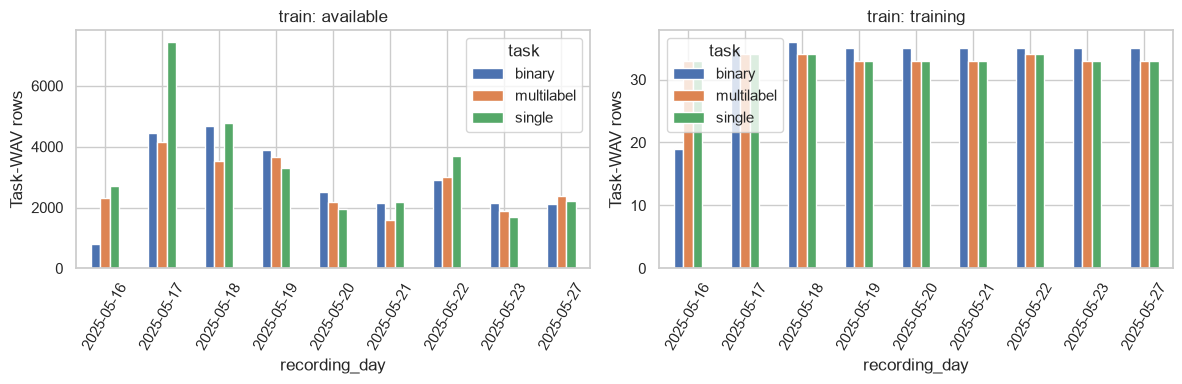

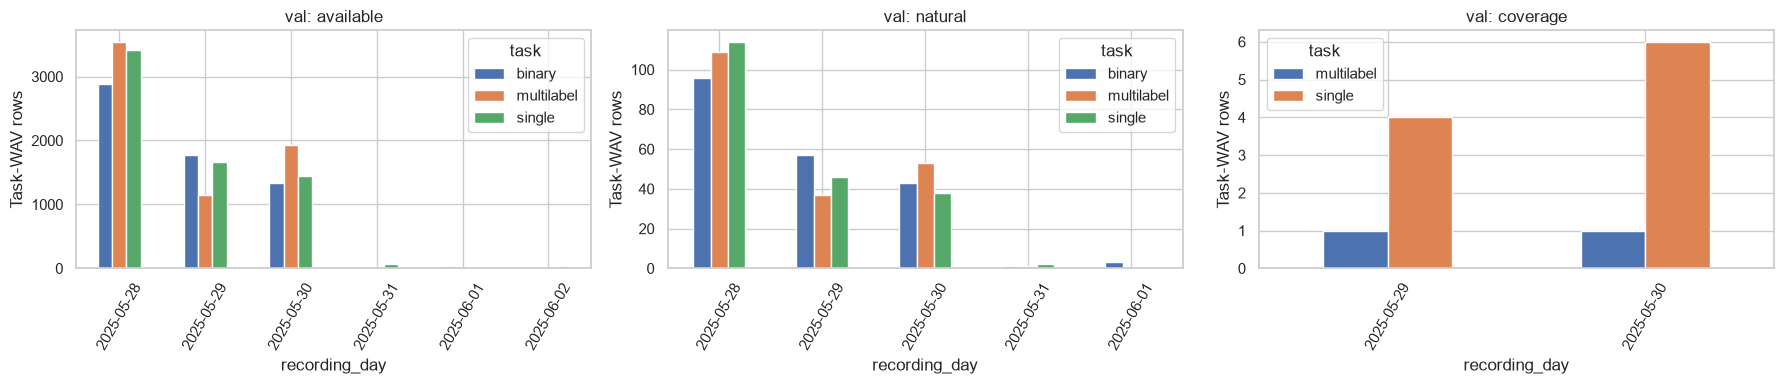

In [4]:
# Official-split overlap uses identities only, including reserved test membership.
official_counts = manifest.groupby(['task', 'official_split'])['audio_path'].nunique()
display(official_counts.unstack().reindex(columns=splits))
official_membership = manifest.groupby(['task', 'audio_path'])['official_split'].nunique()
shared_paths = official_membership.loc[official_membership.gt(1)]
print(f'WAVs shared across official splits: '
      f'{shared_paths.index.get_level_values("audio_path").nunique():,}')

# Common day and WAV assignments must agree across tasks.
identity_tables = [('manifest', manifest, 'temporal_split'), ('pilot', pilot, 'split')]
for name, table, split_column in identity_tables:
    wav_splits = table.groupby('audio_path')[split_column].nunique()
    day_splits = table.groupby('recording_day')[split_column].nunique()
    print(f'{name}: WAVs crossing temporal splits = {wav_splits.gt(1).sum()}')
    print(f'{name}: recording days crossing temporal splits = {day_splits.gt(1).sum()}')
split_mismatches = pilot['split'].ne(pilot['temporal_split']).sum()
print(f'Pilot split differs from temporal_split: {split_mismatches}')
validation_membership = selected.loc[selected['split'].eq('val')]
keys = ['task', 'audio_path']
natural_keys = validation_membership.loc[validation_membership['view'].eq('natural'), keys]
coverage_keys = validation_membership.loc[validation_membership['view'].eq('coverage'), keys]
shared_validation = natural_keys.merge(coverage_keys, on=keys)
print(f'Natural/coverage shared task-WAVs: {len(shared_validation)}')

# Compare development counts by day, five-minute bin, and vessel-count group.
comparison['vessel_count_group'] = pd.cut(
    comparison['n_vessels'], bins=[-1, 0, 1, 2, np.inf], labels=['0', '1', '2', '3+'],
)
comparison['vessel_count_group'] = (
    comparison['vessel_count_group'].cat.add_categories('unknown').fillna('unknown')
)
print('Development rows, days, and time bins by view:')
display(comparison.groupby(['task', 'split', 'view']).agg(
    rows=('audio_path', 'size'), days=('recording_day', 'nunique'),
    time_bins=('time_bin', 'nunique'),
))
for dimension in ['recording_day', 'time_bin', 'vessel_count_group']:
    print(f'Development available versus selected: {dimension}')
    counts = comparison.groupby(['task', 'split', dimension, 'view'], observed=True).size()
    display(counts.unstack('view', fill_value=0).reindex(columns=view_order, fill_value=0))

# Known dataset serializations contain nine-digit AIS identifier tokens.
id_rows = []
for (task, split, view), group in comparison.groupby(['task', 'split', 'view']):
    unique_ids = (
        group['all_mmsis'].dropna().astype(str).str.findall(r'\b\d{9}\b').explode().nunique()
    )
    id_rows.append({
        'task': task, 'split': split, 'view': view, 'unique_ids': unique_ids,
        'source': 'all_mmsis',
    })
id_counts = pd.DataFrame(id_rows)
print('Unique AIS identifiers, not unique audible vessels:')
display(id_counts)

# Each development view has its own day distribution.
for split in development_splits:
    split_views = ['available', 'training']
    if split == 'val':
        split_views = ['available', 'natural', 'coverage']
    fig, axes = plt.subplots(
        1, len(split_views), figsize=(6 * len(split_views), 4), squeeze=False,
    )
    for ax, view in zip(axes[0], split_views):
        group = comparison.loc[comparison['split'].eq(split) & comparison['view'].eq(view)]
        if group.empty:
            ax.set_title(f'{split}: {view} (empty)')
            continue
        daily_counts = group.groupby(['recording_day', 'task']).size().unstack(fill_value=0)
        daily_counts.plot.bar(ax=ax, rot=60, title=f'{split}: {view}')
        ax.set_ylabel('Task-WAV rows')
    fig.tight_layout()
    plt.show()

## 4. Check a few recordings

Check the persisted preparation diagnostics for selected development recordings, then listen to three binary-training examples. This says nothing about audio quality across the whole archive. No test audio is opened, and quiet recordings are not rejected merely for being quiet.

Review the original AIS metadata beside the audio, without changing its labels. AIS presence does not establish audibility or precise AIS/audio alignment.

Waveform values are digital amplitudes, not calibrated sound pressure. Playback and spectrograms average the channels, which can lose information.

In [5]:
# Read preparation diagnostics, without opening selected or reserved-test WAVs.
selected_paths = selected['audio_path'].drop_duplicates()
audio_info = audio_quality.loc[audio_quality['audio_path'].isin(selected_paths)].copy()
print(
    f'{len(audio_info)} persisted development quality rows '
    f'for {len(selected_paths)} selected WAVs.'
)
missing_diagnostics = set(selected_paths) - set(audio_info['audio_path'])
print(f'Selected development WAVs without diagnostics: {len(missing_diagnostics)}')
quality_columns = [
    'frames', 'duration', 'sample_rate', 'channels', 'rms', 'peak', 'clipping_fraction',
]
display(audio_info[quality_columns].describe())
status_counts = audio_info.groupby(['status', 'reason'], dropna=False).size().rename('wavs')
display(status_counts.to_frame())
display(audio_info['silent'].value_counts(dropna=False).rename('wavs').to_frame())

# Include all persisted statuses for excluded development WAVs, including invalid audio.
excluded_quality = audio_quality.loc[
    audio_quality['audio_path'].isin(development_exclusions['audio_path'])
]
print('Preparation quality for excluded development WAVs (all statuses):')
display(excluded_quality)

# Display flags for review; silence or clipping alone does not imply exclusion.
flagged = audio_info['frames'].fillna(0).lt(2) | audio_info['clipping_fraction'].gt(0)
flagged |= audio_info['silent'].astype('string').str.lower().isin(['true', '1'])
display(audio_info.loc[flagged, [
    'audio_path', 'status', 'frames', 'duration', 'rms', 'peak', 'silent',
    'clipping_fraction', 'reason',
]])

1506 persisted development quality rows for 1506 selected WAVs.
Selected development WAVs without diagnostics: 0


,frames,duration,sample_rate,channels,rms,peak,clipping_fraction
count,1506.0,1506.0,1506.0,1506.0,1506.000000,1.506000e+03,1506.000000
mean,96000.0,3.0,32000.0,4.0,0.102934,1.000000e+00,0.001676
std,0.0,0.0,0.0,0.0,0.062963,7.863893e-07,0.009938
min,96000.0,3.0,32000.0,4.0,0.038259,9.999695e-01,0.000008
25%,96000.0,3.0,32000.0,4.0,0.068190,1.000000e+00,0.000224
50%,96000.0,3.0,32000.0,4.0,0.087330,1.000000e+00,0.000362
75%,96000.0,3.0,32000.0,4.0,0.115427,1.000000e+00,0.000557
max,96000.0,3.0,32000.0,4.0,0.696149,1.000000e+00,0.210107


,,wavs
status,reason,
valid,NaN,1506


,wavs
silent,
False,1506


Preparation quality for excluded development WAVs (all statuses):


,audio_path,status,reason,frames,sample_rate,channels,duration,rms,peak,silent,clipping_fraction
558,20250516_184403.019908949.wav,valid,NaN,96000,32000,4,3.0,0.063556,1.0,False,0.000109
600,20250516_165226.317033873.wav,valid,NaN,96000,32000,4,3.0,0.125094,1.0,False,0.003742
623,20250516_170541.827926059.wav,valid,NaN,96000,32000,4,3.0,0.101436,1.0,False,0.000266
633,20250516_165627.124425619.wav,valid,NaN,96000,32000,4,3.0,0.160527,1.0,False,0.011724
643,20250516_174403.058446476.wav,valid,NaN,96000,32000,4,3.0,0.083184,1.0,False,0.000508
670,20250516_172028.873788058.wav,valid,NaN,96000,32000,4,3.0,0.152093,1.0,False,0.007724
742,20250516_174754.671962666.wav,valid,NaN,96000,32000,4,3.0,0.076145,1.0,False,0.000109
778,20250516_170003.616161526.wav,valid,NaN,96000,32000,4,3.0,0.169563,1.0,False,0.010156
960,20250528_005120.865557977.wav,valid,NaN,96000,32000,4,3.0,0.106629,1.0,False,0.000523
1058,20250516_171600.701936528.wav,valid,NaN,96000,32000,4,3.0,0.203599,1.0,False,0.012021


,audio_path,status,frames,duration,rms,peak,silent,clipping_fraction,reason
0,20250520_104103.808495310.wav,valid,96000,3.0,0.143063,1.0,False,0.000732,NaN
1,20250517_204701.102337046.wav,valid,96000,3.0,0.273373,1.0,False,0.010974,NaN
2,20250523_080848.437060648.wav,valid,96000,3.0,0.117642,1.0,False,0.000815,NaN
3,20250519_105722.863658450.wav,valid,96000,3.0,0.118282,1.0,False,0.000432,NaN
4,20250518_002350.271969667.wav,valid,96000,3.0,0.091101,1.0,False,0.001026,NaN
...,...,...,...,...,...,...,...,...,...
1502,20250530_175656.185633973.wav,valid,96000,3.0,0.123731,1.0,False,0.002828,NaN
1503,20250528_195703.500442288.wav,valid,96000,3.0,0.134584,1.0,False,0.000646,NaN
1504,20250530_192307.842003714.wav,valid,96000,3.0,0.073722,1.0,False,0.000193,NaN
1505,20250530_120952.336134925.wav,valid,96000,3.0,0.059966,1.0,False,0.000122,NaN


,audio_path,source,is_background,n_vessels,primary_mmsi,primary_class,primary_dist,all_mmsis,timestamp,tug,...,other_dist,split,binary_label,task,official_split,window_start,recording_day,time_bin,temporal_split,conflicting_target
32075,20250518_162434.151252286.wav,background,1,0,<NA>,NaN,NaN,<NA>,2025-05-18 16:24:34+00:00,0,...,NaN,train,0.0,binary,test,2025-05-18 16:24:34.151252286+00:00,2025-05-18,2025-05-18 16:20:00+00:00,train,False


20250518_162434.151252286.wav: binary=0, vessels=0


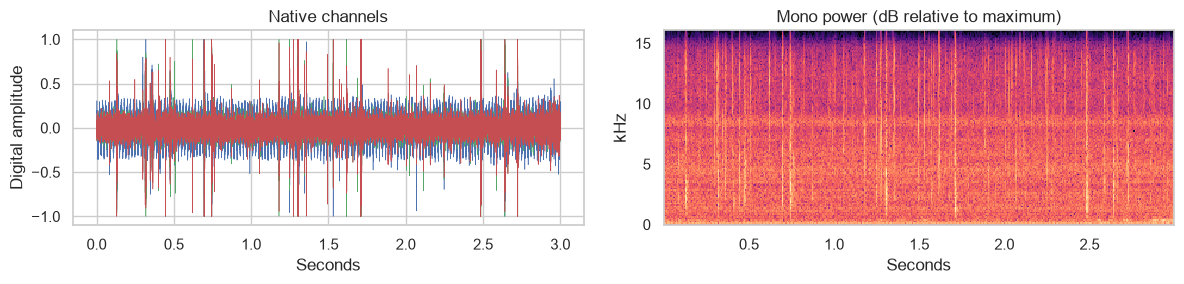

,audio_path,source,is_background,n_vessels,primary_mmsi,primary_class,primary_dist,all_mmsis,timestamp,tug,...,other_dist,split,binary_label,task,official_split,window_start,recording_day,time_bin,temporal_split,conflicting_target
9846,20250527_182616.451108576.wav,background,1,0,<NA>,NaN,NaN,<NA>,2025-05-27 18:26:16+00:00,0,...,NaN,train,0.0,binary,train,2025-05-27 18:26:16.451108576+00:00,2025-05-27,2025-05-27 18:25:00+00:00,train,False


20250527_182616.451108576.wav: binary=0, vessels=0


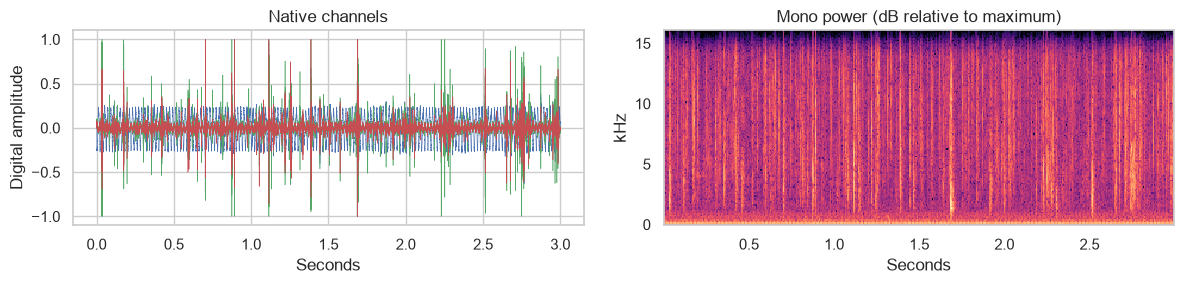

,audio_path,source,is_background,n_vessels,primary_mmsi,primary_class,primary_dist,all_mmsis,timestamp,tug,...,other_dist,split,binary_label,task,official_split,window_start,recording_day,time_bin,temporal_split,conflicting_target
234,20250516_182325.304563749.wav,background,1,0,<NA>,NaN,NaN,<NA>,2025-05-16 18:23:25+00:00,0,...,NaN,train,0.0,binary,train,2025-05-16 18:23:25.304563749+00:00,2025-05-16,2025-05-16 18:20:00+00:00,train,False


20250516_182325.304563749.wav: binary=0, vessels=0


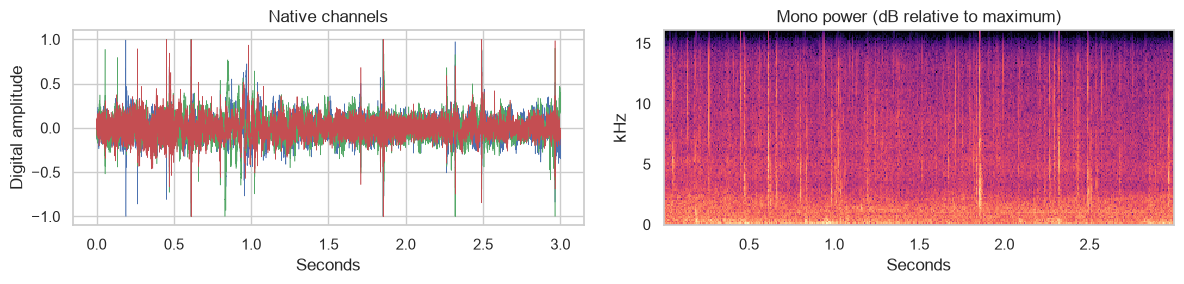

In [6]:
# Keep three fixed binary-training examples, never validation or reserved test.
examples = selected.loc[selected['task'].eq('binary') & selected['split'].eq('train')
                        & selected['view'].eq('training')]
examples = examples.drop_duplicates('audio_path')
examples = examples.sample(n=min(3, len(examples)), random_state=42)

for row in examples.itertuples(index=False):
    # Original AIS metadata is for review, not manual relabeling.
    original_metadata = development.loc[
        development['task'].eq('binary') & development['audio_path'].eq(row.audio_path)
    ]
    display(original_metadata)
    try:
        samples, rate = sf.read(audio_dir / row.audio_path, always_2d=True)
    except (OSError, RuntimeError) as error:
        print(f'Skipping {row.audio_path}: {error}')
        continue
    if len(samples) < 2 or not np.isfinite(samples).all():
        print(f'Skipping {row.audio_path}: short or nonfinite samples')
        continue

    # Show each channel, then use their mean for playback and the spectrum.
    mono = samples.mean(axis=1)
    frequencies, times, power = signal.spectrogram(mono, fs=rate)
    relative_power = power / max(power.max(), np.finfo(float).tiny)
    relative_db = 10 * np.log10(np.maximum(relative_power, 1e-10))

    print(f'{row.audio_path}: binary={row.binary_label:g}, vessels={row.n_vessels}')
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    axes[0].plot(np.arange(len(samples)) / rate, samples, linewidth=0.4)
    axes[0].set(title='Native channels', xlabel='Seconds', ylabel='Digital amplitude')
    axes[1].pcolormesh(times, frequencies / 1000, relative_db,
                       shading='auto', cmap='magma', vmin=-100, vmax=0)
    axes[1].set(title='Mono power (dB relative to maximum)',
                xlabel='Seconds', ylabel='kHz')
    fig.tight_layout()
    plt.show()
    display(Audio(mono, rate=rate, normalize=False))